In [1]:

from typing import List, TypedDict, Literal
from pydantic import BaseModel,Field

import os
import re

from dotenv import load_dotenv

# PDF loader
from langchain_community.document_loaders import PyPDFLoader

# FAISS
from langchain_community.vectorstores import FAISS

# Local Ollama models
from langchain_ollama import ChatOllama, OllamaEmbeddings

# Text splitting
from langchain_text_splitters import RecursiveCharacterTextSplitter

# Documents and prompts
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

# LangGraph
from langgraph.graph import StateGraph, START, END

# Tavily (optional external web search)
from langchain_tavily import TavilySearch
from langchain_tavily import TavilySearch

C:\Users\rahul\AppData\Local\Temp\ipykernel_29532\1733710168.py:10: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [2]:
load_dotenv()

True

In [3]:
# Local LLM
llm = ChatOllama(
    model="llama3.2:3b",
    temperature=0
)

In [4]:
# Test LLM
response = llm.invoke("Explain quantum mechanics in 3 lines.")

print(response.content)

Quantum mechanics is a branch of physics that describes the behavior of matter and energy at the smallest scales, where particles can exist in multiple states and locations simultaneously. This is known as superposition, and it's a fundamental aspect of quantum mechanics. The act of observing or measuring these particles can also change their behavior, a phenomenon known as wave function collapse.


In [5]:
docs = (
    PyPDFLoader("C:/Users/rahul/CRAG/world_history_detailed_expanded_60_pages.pdf").load()
)

# RAG Components using langchain

In [6]:
chunks = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150).split_documents(docs) #list of docs
for d in chunks:
    d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")
    print(d.page_content)

WORLD HISTORY  EXPANDED STUDY EDITION
1 / 60
WORLD HISTORY
A Detailed Journey Through World History
 Expanded study edition  60 pages
WHAT THIS EDITION COVERS
Early humans and agriculture  Ancient Africa, Asia, Europe and the Americas  Classical empires  Medieval trade and belief  Renaissance and
Reformation  Oceanic expansion and slavery  Scientific thought and revolutions  Industrialisation and imperialism  World wars  Decolonisation 
Cold War  Globalisation and the 21st century
This expanded guide develops the earlier edition with fuller explanations, connected narratives, context, turning points, consequences and revision prompts.
It is designed as an accessible introduction, not a substitute for specialist scholarship.
 Dates use BCE (Before Common Era) and CE (Common Era). Ancient dates may be approximate.
WORLD HISTORY  EXPANDED STUDY EDITION
2 / 60
CHRONOLOGICAL SECTION 02
TOPIC 01  Each chapter separates background, event, outcome and historical significance.
Ho

In [7]:
# pip install langchain-huggingface sentence-transformers
from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(
    model_name="BAAI/bge-small-en-v1.5",
    model_kwargs={"device": "cpu"},                 # "cuda" if your PyTorch build has CUDA
    encode_kwargs={"normalize_embeddings": True},
)

vec = embeddings.embed_query("What is Newton's second law?")
print(len(vec))     # 384 for bge-small

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

384


In [8]:
vec

[-0.09174162149429321,
 -0.026504864916205406,
 -0.03963166102766991,
 -0.029972538352012634,
 -0.043841652572155,
 0.02592843398451805,
 0.03672304376959801,
 0.019649066030979156,
 0.04305955022573471,
 0.011663490906357765,
 -0.014537322334945202,
 -0.10648752748966217,
 0.026291726157069206,
 -0.00890127569437027,
 -0.033378154039382935,
 -0.0426400825381279,
 0.04208553209900856,
 0.041376661509275436,
 -0.0711357444524765,
 0.020412560552358627,
 0.12484367936849594,
 -0.005166425835341215,
 0.004432025831192732,
 -0.033825453370809555,
 0.042766064405441284,
 0.0889788493514061,
 -0.07371935993432999,
 0.038877375423908234,
 -0.07726983726024628,
 -0.1607254445552826,
 0.007558668497949839,
 -0.08294376730918884,
 0.0021334777120500803,
 0.005253762938082218,
 0.022868508473038673,
 -0.06207567825913429,
 -0.002825760515406728,
 -0.0023602296132594347,
 0.035082340240478516,
 0.04012436792254448,
 -0.04687589406967163,
 0.006838413421064615,
 0.022433985024690628,
 -0.0120337447

In [9]:
#embeddings = OpenAIEmbeddings(model="text-embedding-3-large")
vector_store = FAISS.from_documents(chunks, embeddings)
retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})

In [10]:
# Local LLM
llm = ChatOllama(
    model="llama3.2:3b",
    temperature=0
)

In [11]:
class State(TypedDict):
    question: str

    docs: List[Document]
    good_docs: List[Document]

    verdict: str
    reason: str

    strips: List[str]
    filtered_strips: List[str]
    refined_context: str

    web_query: str
    
    web_docs: List[Document]

    answer: str

In [12]:
# -----------------------------
# Retrieve
# -----------------------------
def retrieve_node(state: State) -> State:
    q = state["question"]
    return {"docs": retriever.invoke(q)}

In [13]:
doc_eval_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You grade whether a text chunk helps answer a question.\n\n"
     "Pick exactly ONE score:\n"
     "1.0 = the chunk directly answers the question on its own\n"
     "0.7 = the chunk has part of the answer or key facts, but something is missing\n"
     "0.3 = the chunk is on the same topic but does not help answer the question\n"
     "0.0 = the chunk is unrelated to the question\n\n"
     "Rules:\n"
     "- Judge ONLY from the chunk. Do not use your own knowledge.\n"
     "- Sharing a few keywords with the question does not make a chunk relevant.\n"
     "- If unsure between two scores, pick the lower one.\n\n"
     "Reply with JSON only, in exactly this format:\n"
     '{{"reason": "<one short sentence>", "score": <0.0 or 0.3 or 0.7 or 1.0>}}'),
    # --- the real input ---
    ("human", "Question: {question}\n\nChunk:\n{chunk}"),
])
class RetrievalEvaluation(BaseModel):
    score: float = Field(
        description="Relevance score between 0 and 1"
    )
    reason: str = Field(
        description="Brief explanation for the evaluation"
    )
llm_knowledge_evaluator = llm.with_structured_output(
    RetrievalEvaluation
)
def knowledge_evaluation(state:State)->State:
    docs = state["docs"] #list of chunks
    q = state["question"]
    UPPER_TH = 0.7
    LOWER_TH = 0.3
    corr_chunk = []
    incorr_chunk = []
    for d in docs:
        chunk = d.page_content
        prompt = doc_eval_prompt.invoke({"question":q,"chunk":chunk})
        score = llm_knowledge_evaluator.invoke(prompt).score
        if score >= UPPER_TH:
            corr_chunk.append(d)
        else:
            if score <= LOWER_TH:
                incorr_chunk.append(d)
    if len(corr_chunk)>0:
        verdict = "CORRECT"
        #reason = 
    else:
        if len(incorr_chunk) == len(docs):
            verdict = "INCORRECT"
        else:
            verdict = "AMBIGUOUS"
    return {"good_docs":corr_chunk,"verdict":verdict}
   

In [14]:
#STRIPS

In [15]:
def decompose_to_sentences(text: str) -> List[str]:
    text = re.sub(r"\s+", " ", text).strip()
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [s.strip() for s in sentences if len(s.strip()) > 20]

In [16]:
from langchain_core.prompts import ChatPromptTemplate

knowledge_correction_prompt = ChatPromptTemplate.from_messages([

    ("system", """
    You are a knowledge refinement assistant.

    Your task is to filter a list of knowledge strips based on
    their relevance to the given question.

    Instructions:
    1. Carefully examine each knowledge strip independently.
    2. Retain only strips that contain useful information for
       answering the question.
    3. Remove irrelevant, redundant, misleading, or unrelated strips.
    4. A strip does not need to answer the entire question.
       Retain it if it provides a useful fact or partial information.
    5. Do not add information from your own knowledge.
    6. Do not rewrite or modify the original strips.
    7. Preserve the original wording of retained strips.
    8. If no strips are relevant, return an empty list.

    Return the result using the specified structured output.
    """),

    ("human", """
    Question:
    {question}

    Knowledge Strips:
    {strips}
    """)
])
class KnowledgeCorrection(BaseModel):
    good_strips: List[str] = Field(
        description="List of knowledge strips relevant to answering the question"
    )
llm_strips_filter = llm.with_structured_output(KnowledgeCorrection)

In [17]:
def refine(state:State)->State:
    #lets construct context from corr_chunk
    q = state["question"]
    strips = []
    if state["verdict"]=="CORRECT":
        docs = state["good_docs"]
    else:
        if state["verdict"] == "INCORRECT":
            docs = state["web_docs"]
        else:
            l1 = state["good_docs"]
            l2 = state["web_docs"]
            docs = l1.extend(l2)
    for d in docs:
        strip_list = decompose_to_sentences(d.page_content)
        strips.extend(strip_list)
    prompt = knowledge_correction_prompt.invoke({"question":q,"strips":strips})
    good_strips = llm_strips_filter.invoke(prompt).good_strips
    return {"strips":strips,"filtered_strips":good_strips}

In [18]:
prompt_temp = ChatPromptTemplate.from_messages([
    ("human", """
    Question: {question}

    Context: {context}

    Answer using the given context.
    """)
])
def generate(state:State)->State:
    context = ""
    q = state["question"]
    docs = state["filtered_strips"]
    for d in docs:
        context = context+" "+d
    prompt = prompt_temp.invoke({"question":q,"context":context})
    answer = llm.invoke(prompt)
    return {"answer":answer}

In [19]:
# -----------------------------
# Query rewrite for web search
# -----------------------------
import os
from langchain_community.tools.tavily_search import TavilySearchResults
#os.environ["TAVILY_API_KEY"] = "tvly-43z6aW-T9dfNg1UijVCxQSCOtjWy9pWm0KkgaTxg43ViTLujA"
tavily = TavilySearchResults(max_results=5)


class WebQuery(BaseModel):
    query: str


rewrite_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Rewrite the user question into a web search query composed of keywords.\n"
            "Rules:\n"
            "- Keep it short (6–14 words).\n"
            "- If the question implies recency (e.g., recent/latest/last week/last month), add a constraint like (last 30 days).\n"
            "- Do NOT answer the question.\n"
            "- Return JSON with a single key: query",
        ),
        ("human", "Question: {question}"),
    ]
)

rewrite_chain = rewrite_prompt | llm.with_structured_output(WebQuery)


def rewrite_query_node(state: State) -> State:
    out = rewrite_chain.invoke({"question": state["question"]})
    return {"web_query": out.query}

# -----------------------------
# Web search node: uses web_query
# -----------------------------
tavily = TavilySearchResults(max_results=5)


def web_search_node(state: State) -> State:
    q = state.get("web_query") or state["question"]
    results = tavily.invoke({"query": q})

    web_docs: List[Document] = []
    for r in results or []:
        title = r.get("title", "")
        url = r.get("url", "")
        content = r.get("content", "") or r.get("snippet", "")
        text = f"TITLE: {title}\nURL: {url}\nCONTENT:\n{content}"
        web_docs.append(Document(page_content=text, metadata={"url": url, "title": title}))

    return {"web_docs": web_docs}

C:\Users\rahul\AppData\Local\Temp\ipykernel_29532\3455813034.py:7: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily = TavilySearchResults(max_results=5)


In [20]:
# Routing
# CORRECT => refine
# INCORRECT / AMBIGUOUS => rewrite -> web_search -> refine -> generate
# -----------------------------
def route_after_eval(state: State) -> str:
    if state["verdict"] == "CORRECT":
        return "refine"
    else:
        return "rewrite_query"

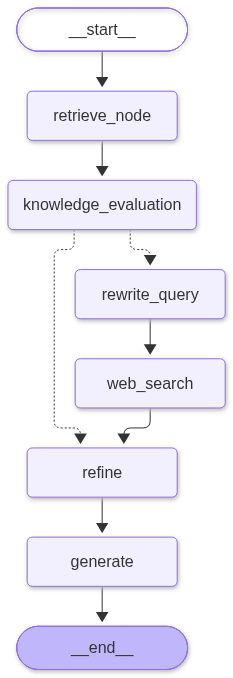

In [21]:
# -----------------------------
# Build graph
# -----------------------------
g = StateGraph(State)

g.add_node("retrieve_node", retrieve_node)
g.add_node("knowledge_evaluation", knowledge_evaluation)

g.add_node("rewrite_query", rewrite_query_node)
g.add_node("web_search", web_search_node)

g.add_node("refine", refine)
g.add_node("generate", generate)

g.add_edge(START, "retrieve_node")
g.add_edge("retrieve_node", "knowledge_evaluation")

g.add_conditional_edges(
    "knowledge_evaluation",
    route_after_eval,
    {
        "refine": "refine",
        "rewrite_query": "rewrite_query",
    },
)
# non-correct path
g.add_edge("rewrite_query", "web_search")
g.add_edge("web_search", "refine")

# correct path already goes to refine
g.add_edge("refine", "generate")
g.add_edge("generate", END)

app = g.compile()

app

In [22]:
# -----------------------------
# Run example
# -----------------------------
res = app.invoke(
    {
        "question": "explain Second World War",
        "docs": [],
        "good_docs": [],
        "verdict": "",
        "reason": "",
        "strips": [],
        "filtered_strips": [],
        "refined_context": "",
        "web_query": "",
        "web_docs": [],
        "answer": "",
    }
)

print("VERDICT:", res["verdict"])
print("REASON:", res["reason"])
print("WEB_QUERY:", res["web_query"])
print("\nOUTPUT:\n", res["answer"])

VERDICT: CORRECT
REASON: 
WEB_QUERY: 

OUTPUT:
 content="Based on the provided context, here's an explanation of the Second World War:\n\n**Setting:** The Second World War began in Europe, but it eventually became a global conflict involving multiple continents, including the Middle East, Africa, Asia-Pacific, and the Americas.\n\n**Causes:**\n\n1. **Nazi Germany's invasion of Poland**: On September 1, 1939, Nazi Germany, led by Adolf Hitler, invaded Poland, which led to the declaration of war by Britain and France two days later.\n2. **Japan's aggressive expansion**: Japan had been expanding its territory in Asia since the 1930s, including the invasion of Manchuria in 1931 and the launch of full-scale war against China in 1937.\n\n**Main turning points in order:**\n\n1. **September 1, 1939**: Nazi Germany invades Poland.\n2. **September 3, 1939**: Britain and France declare war on Germany.\n3. **May 10, 1940**: Germany conquers Denmark, Norway, Belgium, the Netherlands, and Luxembourg

In [23]:
print(res["answer"].content)

Based on the provided context, here's an explanation of the Second World War:

**Setting:** The Second World War began in Europe, but it eventually became a global conflict involving multiple continents, including the Middle East, Africa, Asia-Pacific, and the Americas.

**Causes:**

1. **Nazi Germany's invasion of Poland**: On September 1, 1939, Nazi Germany, led by Adolf Hitler, invaded Poland, which led to the declaration of war by Britain and France two days later.
2. **Japan's aggressive expansion**: Japan had been expanding its territory in Asia since the 1930s, including the invasion of Manchuria in 1931 and the launch of full-scale war against China in 1937.

**Main turning points in order:**

1. **September 1, 1939**: Nazi Germany invades Poland.
2. **September 3, 1939**: Britain and France declare war on Germany.
3. **May 10, 1940**: Germany conquers Denmark, Norway, Belgium, the Netherlands, and Luxembourg.
4. **June 10, 1940**: Italy declares war on France and the United Ki